In [32]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
import sys
import os

# Automatically locate your active Miniconda environment's plugin directory
conda_prefix = os.environ.get("CONDA_PREFIX")
if conda_prefix:
    # On Windows, Conda puts plugin DLLs in Library\bin\gdalplugins
    plugin_path = os.path.join(conda_prefix, "Library", "lib", "gdalplugins")
    os.environ["GDAL_DRIVER_PATH"] = plugin_path
    # Append the main bin directory to the system PATH so dependencies load
    os.environ["PATH"] = os.path.join(conda_prefix, "Library", "lib") + os.pathsep + os.environ["PATH"]

from interpolation_uncertainty import (
    read_file, show_depth,
    build_coverage_mask,
    compute_dominant_angle_radon_transform, compute_local_orientation,
    undo_rotation,
    detect_trackline_positions, assign_depths_to_lines,
    build_uncertainty_raster,
)

# scikit-image functions used directly in notebook cells
from skimage.morphology import opening, thin, disk

import numpy as np
import matplotlib.pyplot as plt

## Trackline Detection via combined Radon Transform and Local Angle Detection

This notebook detects and extracts individual **survey tracklines** from a bathymetric raster by exploiting the linear spatial structure left by vessel survey passes.

**Overall pipeline:**

1. Load the BAG raster 
2. Build a binary coverage mask.
3. Apply morphological filtering to suppress blob-like dense coverage patches, leaving only thin linear trackline structures.
4. Skeletonise the filtered image to single-pixel-width lines.
5. Use the **Radon transform** to estimate the orientations of survey tracklines in the image.
6. Compute the likely orientation of each survey data point in the dataset.
7. Iteratively extract line families: for each dominant angle, rotate the original bathymetry to align it to the vertical axis and sample the points that intersect with the vertical lines defined by the angle peaks
8. For each extracted family, assign real depth values based on original data
9. With each extracted family now consisting of parallel lines, we can process pairs of lines iteratively

For each pair of lines:

10. Interpolated bathymetry values of there are gaps within the lines
11. Compute the uncertainty for each line in the pair using the spectral energy using distance between the pair of lines as "linespacing"
12. Divide each line into subsegments with lengths equal to linespacing and apply spectral energy computation on each subsegment resulting to 2D array of spectral energies
13. Place the computed 2D arrays to the space between the line pairs

After processing all line pairs:

14. Rotate the resulting raster back to its original orientation (negative of dominant angle)
15. Plot the resulting raster

1. Load the BAG raster

Load the BAG (Bathymetric Attributed Grid) raster file. The result is a dict containing the raw 2D depth array and metadata (geotransform, resolution, no-data value). No-data values are **not** masked on load — they are handled explicitly in subsequent steps.

File '../data/raster/H13060_MB_4m_MLLW_3of3.bag' read successfully.
Data shape: 2362 rows x 6506 columns
No-data value: 1000000.0
Resolution: 4.0 m/pixel
Geotransform values--> 
Origin x-coordinate: 302698.0
Pixel width: 4.0
Row rotation: 0.0
Origin y-coordinate: 3361470.0
Column rotation: 0.0
Pixel height: -4.0



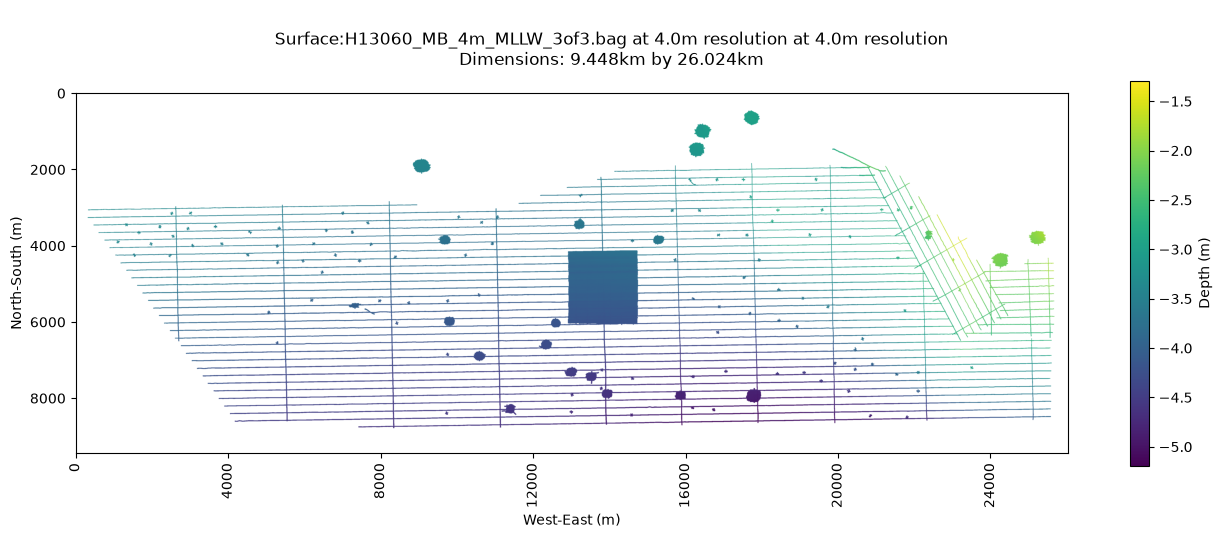

In [34]:
fn = r"../data/raster/H13060_MB_4m_MLLW_3of3.bag"
bathy_data = read_file(fn, verbose=True)

# Visualize the loaded bathymetric data
show_depth(bathy_data, cmap='viridis')

2. Build a binary coverage mask

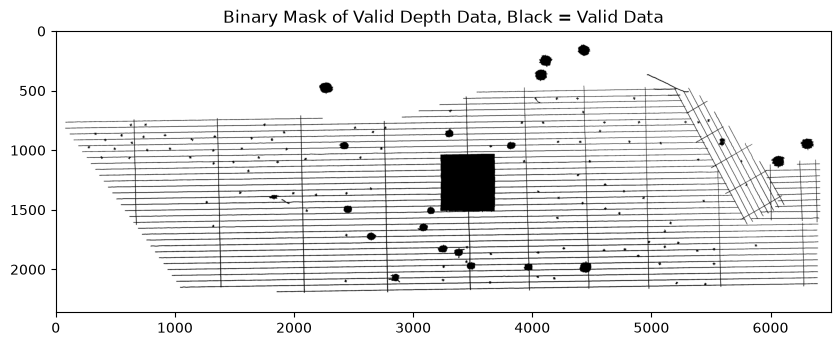

In [35]:
bathy_binary = build_coverage_mask(bathy_data)

plt.figure(figsize=(10, 8))
plt.imshow(1 - bathy_binary, cmap='gray')
plt.title("Binary Mask of Valid Depth Data, Black = Valid Data")
plt.show()

3. Apply morphological filtering to suppress blob-like dense coverage patches, leaving only thin linear trackline structures.

In [36]:
# Apply morphological thinning to the binary mask
# Remove blob-like structures while preserving the skeleton of valid data
bathy_blobs = opening(bathy_binary, disk(5))  # Remove small blobs
bathy_lines = bathy_binary & ~bathy_blobs  # Keep only the line-like structures


4. Skeletonise the filtered image to single-pixel-width lines.

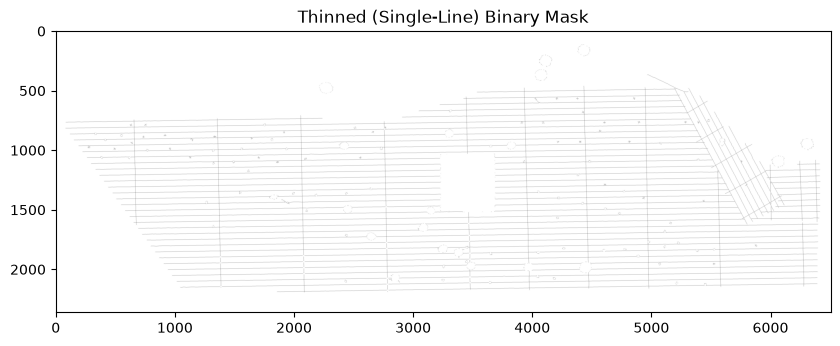

In [37]:
bathy_thin = thin(bathy_lines) > 0
plt.figure(figsize=(10, 8))
plt.imshow(1 - bathy_thin, cmap='gray')
plt.title("Thinned (Single-Line) Binary Mask")
plt.show()

5. Use the **Radon transform** to estimate the orientations of survey tracklines in the image.

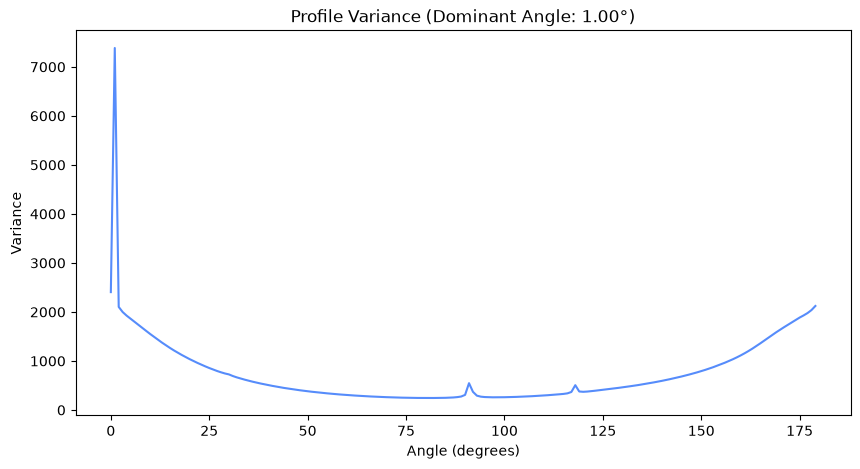

In [38]:
# Run the Radon transform over the full skeleton to identify prominent orientations.
# The variance profile peaks at angles where projections
# are concentrated — characteristic of linear features aligned with that angle.
dominant_orientations = compute_dominant_angle_radon_transform(
    bathy_thin,
    plot_profile_variance=True,
    circle=False
)


In [39]:
print(f"Dominant Orientations: {dominant_orientations['peaks']}")

Dominant Orientations: [  1  91 118]


6. Compute the likely orientation of each survey data point in the dataset.

100%|██████████| 190761/190761 [02:35<00:00, 1229.67it/s]


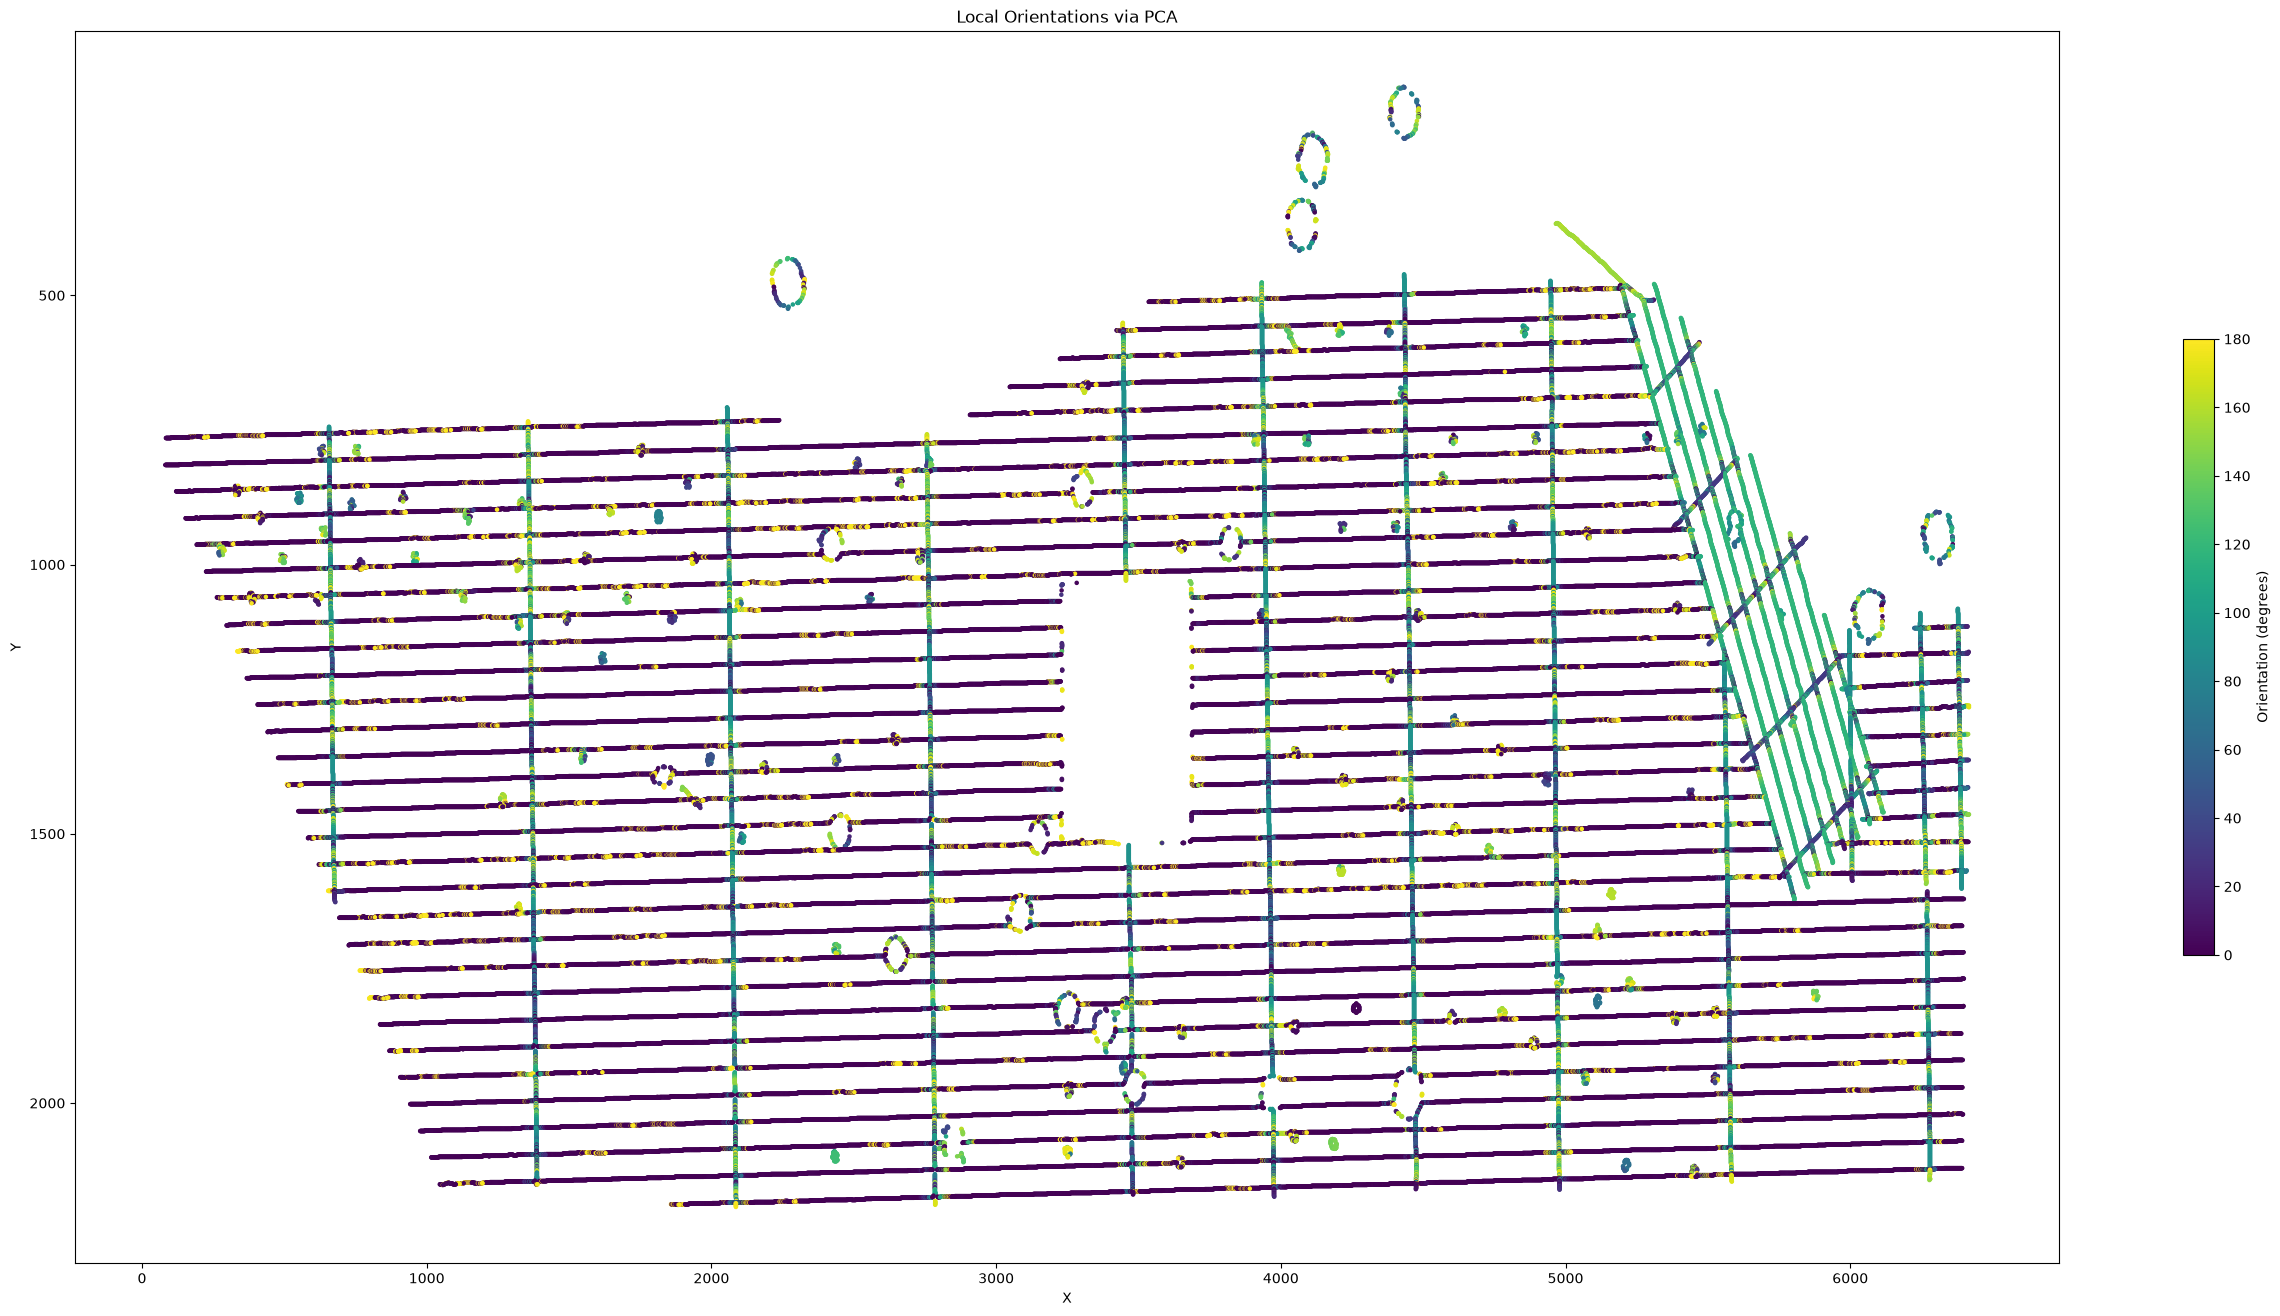

In [40]:
local_orientations = compute_local_orientation(
    binary_image=bathy_thin,
    line_length=50,
    num_neighbors=20,
    plot_orientation=True,
    cmap = 'viridis',
    figsize=(32, 16)
)

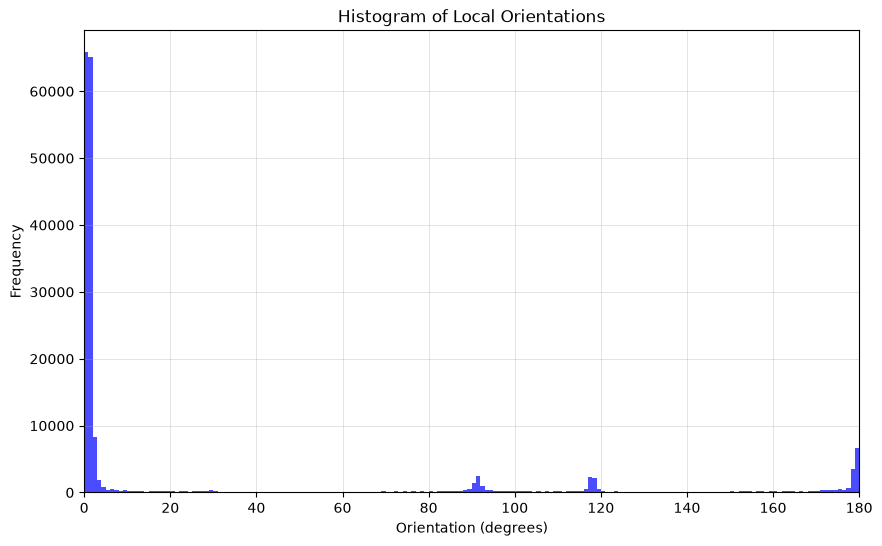

In [43]:
# Compute histogram of local orientations
plt.figure(figsize=(10, 6))
min_angle = np.nanmin(local_orientations)
max_angle = np.nanmax(local_orientations)
plt.hist(local_orientations[~np.isnan(local_orientations)].flatten(), bins=180, range=(min_angle, max_angle), color='blue', alpha=0.7)
plt.title("Histogram of Local Orientations")
plt.xlabel("Orientation (degrees)")
plt.ylabel("Frequency")
plt.xlim(min_angle, max_angle)
plt.grid(True)
plt.show()

7. Iteratively extract line families: for each dominant angle, rotate the original bathymetry to align it to the vertical axis and sample the points that intersect with the vertical lines defined by the angle peaks

In [44]:
TARGET_ANGLES = dominant_orientations['peaks']

# Override detected TARGET_ANGLES as necessary
TARGET_ANGLES = [1, 91]

Using min_line_length = 130 pixels (2.0% of max dimension)
Extracting lines around 1° ± 5°
  Angle range: 176.0° to 6.0°


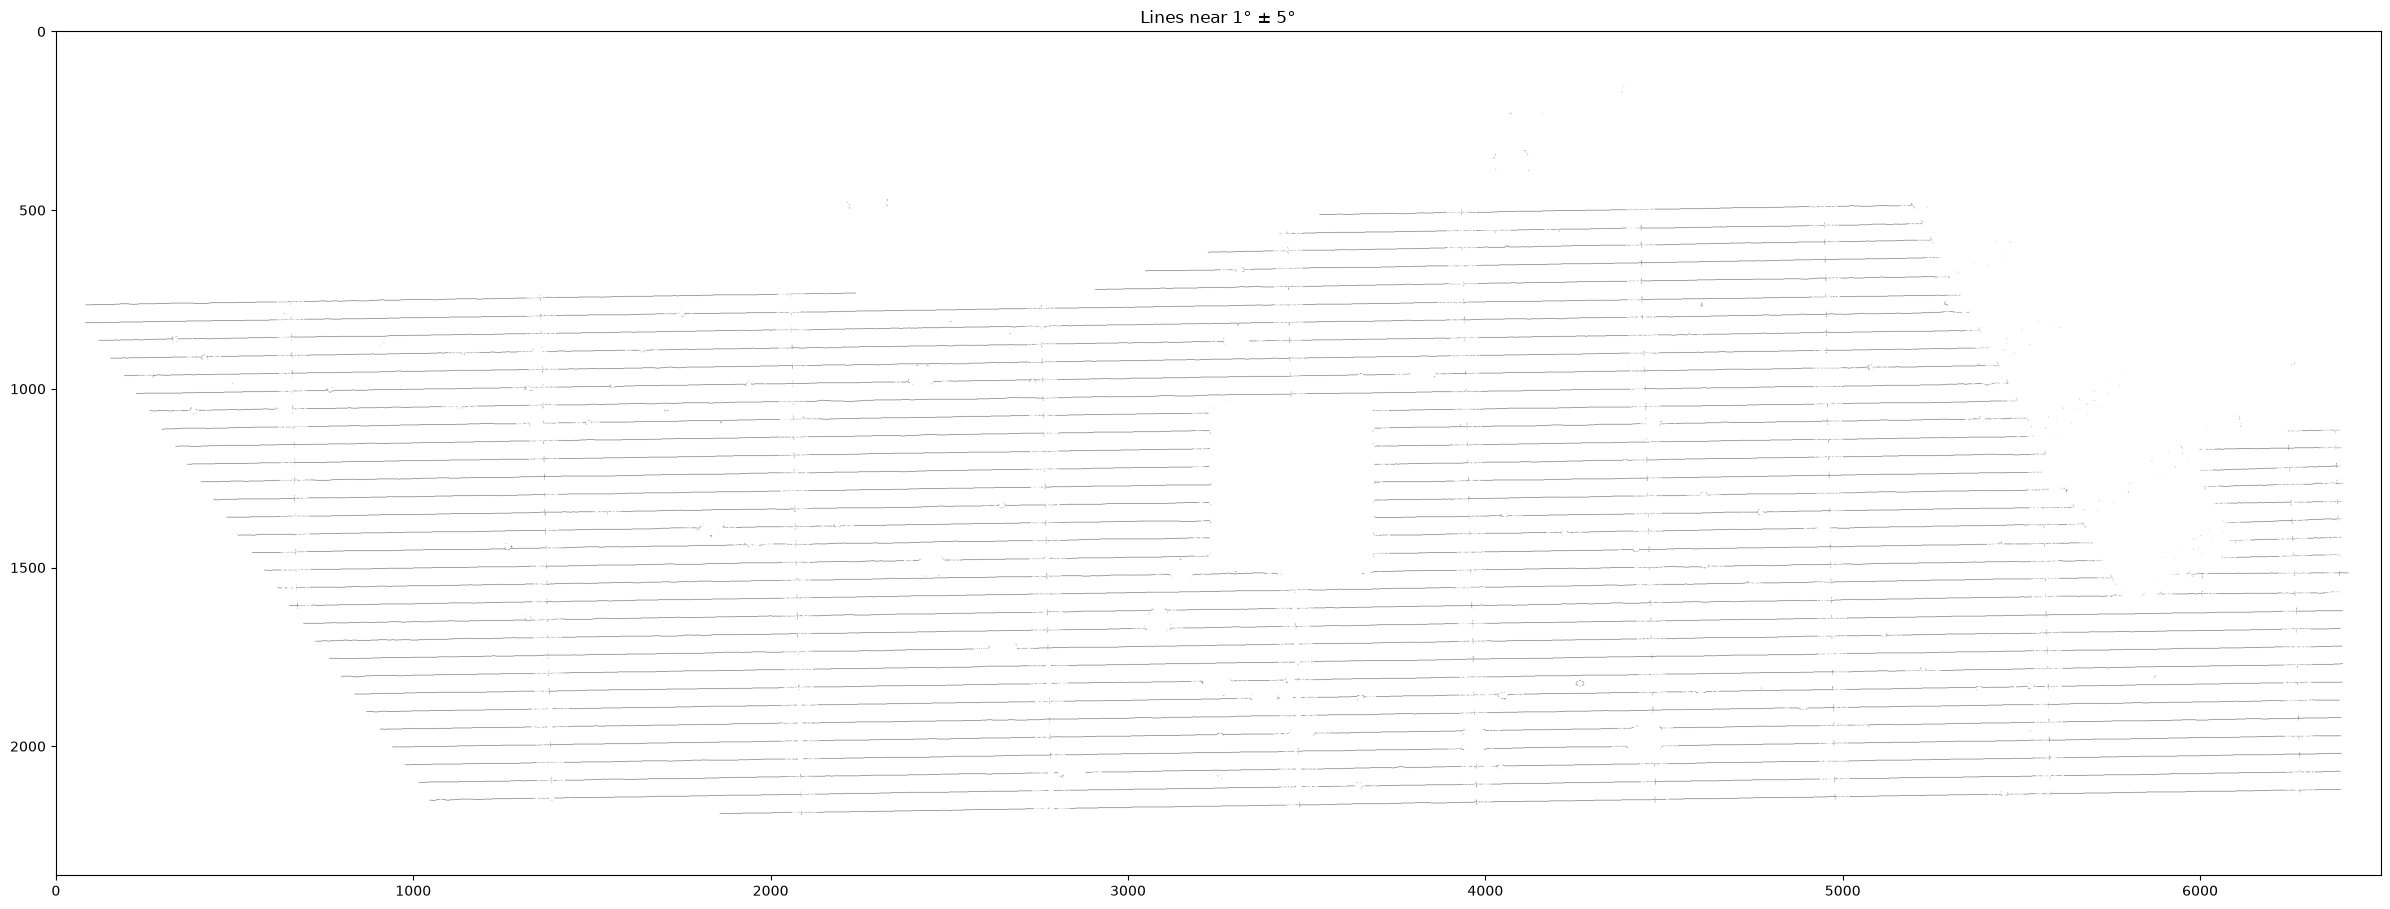

Extracting lines around 91° ± 5°
  Angle range: 86.0° to 96.0°


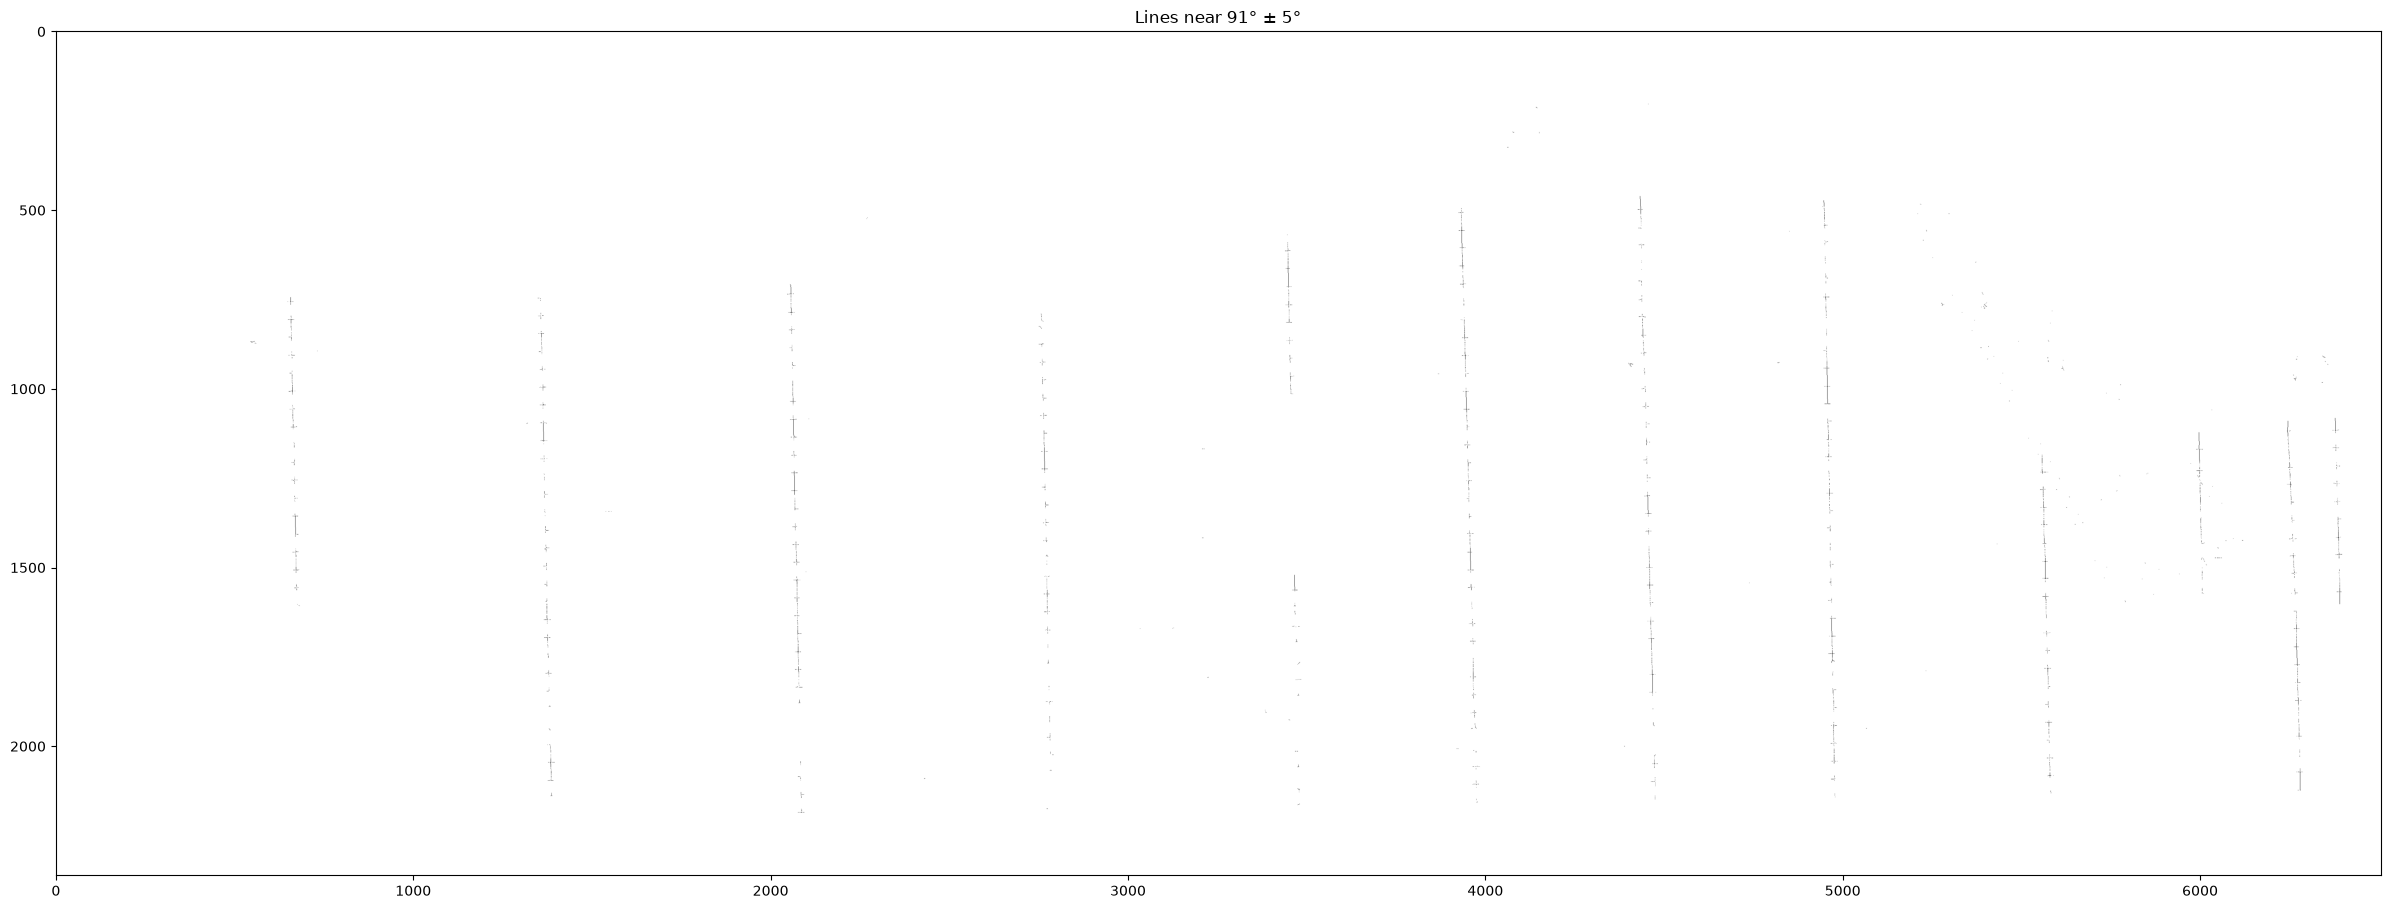

In [45]:
# Use 10% of longest dimension as the minimum line length
# this is a heuristic that captures the scale of features we expect to see
# Adjust as needed for different datasets.
min_line_pct = 0.02
min_line_length = int(min_line_pct * max(bathy_thin.shape))
print(f"Using min_line_length = {min_line_length} pixels "
      f"({min_line_pct*100:.1f}% of max dimension)")


if len(TARGET_ANGLES) > 1:
    angle_search_window = int(np.floor(np.min(np.diff(TARGET_ANGLES))) - 1) // 2
    TOLERANCE = angle_search_window # degrees of tolerance around each target angle
    TOLERANCE = min(TOLERANCE, 5)  # Ensure at least 5 degrees of tolerance
else:
    TOLERANCE = 5

angle_colors = plt.cm.viridis(np.linspace(0, 1, len(TARGET_ANGLES)))

angles_rasters = {}

for i, angle in enumerate(TARGET_ANGLES):
    print(f"Extracting lines around {angle}° ± {TOLERANCE}°")
    # Extract lines near this angle
    low_bound = (angle - TOLERANCE) % 180
    high_bound = (angle + TOLERANCE) % 180
    print(f"  Angle range: {low_bound:.1f}° to {high_bound:.1f}°")
    # Create a mask of pixels whose local orientation falls within this range
    if low_bound < high_bound:
        range_condition = np.logical_and(local_orientations >= low_bound, 
                                         local_orientations < high_bound,
                                         ~np.isnan(local_orientations))
    else:
        range_condition = np.logical_or(local_orientations >= low_bound, 
                                        local_orientations < high_bound,
                                        ~np.isnan(local_orientations))
        
    angles_rasters[angle] = range_condition
    
    plt.figure(figsize=(30, 30))
    plt.imshow(1 - range_condition.astype(bool), cmap='gray')
    plt.title(f"Lines near {angle}° ± {TOLERANCE}°")
    plt.show()

    

7. For each extracted family, assign real depth values based on original data
8. With each extracted family now consisting of parallel lines, we can process pairs of lines iteratively

For each pair of lines:

9. Interpolated bathymetry values of there are gaps within the lines
10. Compute the uncertainty for each line in the pair using the spectral energy using distance between the pair of lines as "linespacing"
11. Divide each line into subsegments with lengths equal to linespacing and apply spectral energy computation on each subsegment resulting to 2D array of spectral energies
12. Place the computed 2D arrays to the space between the line pairs

After processing all line pairs:

13. Rotate the resulting raster back to its original orientation (negative of dominant angle)
14. Plot the resulting raster

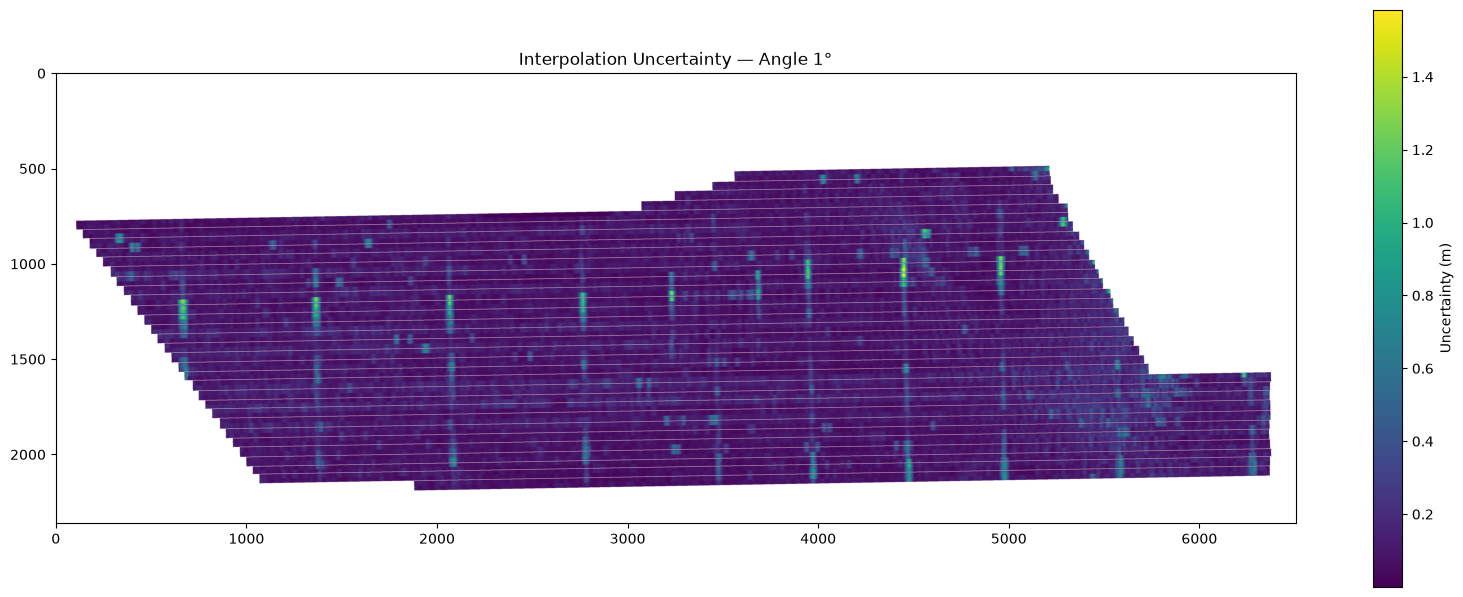

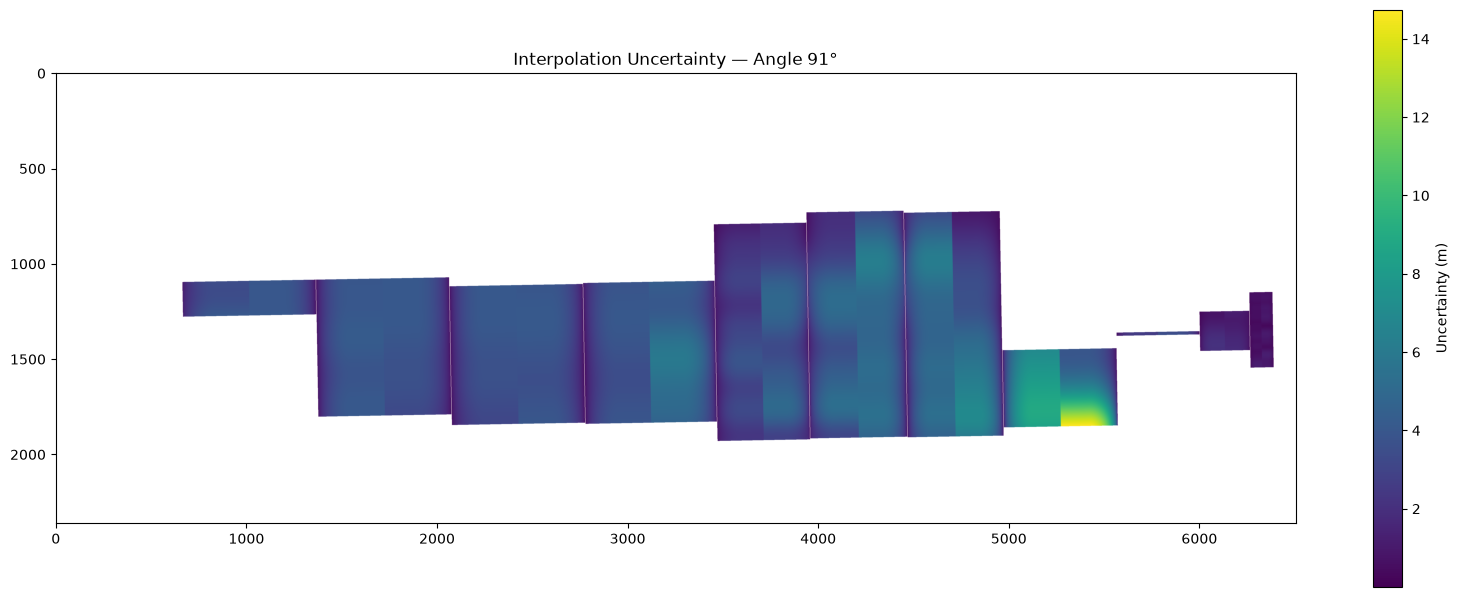

In [46]:
min_line_factor = 0.1  # fraction of max projection height used as the peak threshold
band_width      = 40   # minimum column separation between adjacent detected peaks (pixels)

uncertainty_results = {}  # keyed by angle — stores the final uncertainty raster per family
depth_rasters = {}

for angle in TARGET_ANGLES:
    current_mask = angles_rasters[angle]

    # --- Steps 7–8: Detect trackline positions and build the clean line mask ---
    peaks, restored_mask, angle_to_rotate = detect_trackline_positions(
        angle_mask=current_mask,
        bathy_binary=bathy_binary,
        angle=angle,
        min_line_factor=min_line_factor,
        band_width=band_width,
    )
    # print(f"Angle {angle}°: detected {len(peaks)} tracklines at columns {peaks}")

    # Plot restored mask
    # plt.figure(figsize=(10, 8))
    # plt.imshow(1 - restored_mask, cmap='gray')
    # plt.title("Single Line Trackline Mask")


    # Assign real depth values from bathy_data to each detected line pixel
    current_depth_raster = assign_depths_to_lines(
        restored_mask=restored_mask,
        bathy_binary=bathy_binary,
        bathy_data=bathy_data,
        angle_to_rotate=angle_to_rotate,
    )

    depth_rasters[angle] = current_depth_raster

    # --- Steps 9–12: Process all adjacent line pairs → uncertainty raster ---
    uncertainty_raster = build_uncertainty_raster(
        peaks=peaks,
        restored_mask=restored_mask,
        current_depth_raster=current_depth_raster,
        resolution=bathy_data['metadata']['resolution'],
    )

    # --- Step 13: Rotate uncertainty raster back to original orientation ---
    uncertainty_original = undo_rotation(
        raster=uncertainty_raster,
        angle_to_rotate=angle_to_rotate,
        original_shape=current_mask.shape,
    )

    uncertainty_results[angle] = uncertainty_original

    # --- Step 14: Plot ---
    plt.figure(figsize=(20, 15))
    plt.imshow(uncertainty_original, cmap='viridis')
    plt.colorbar(label='Uncertainty (m)', shrink=0.5)
    plt.title(f'Interpolation Uncertainty — Angle {angle}°')
    plt.show()


In [22]:
## ── Method comparison ────────────────────────────────────────────────────────
# Run the pipeline for every spectral method in compute_uncertainty and display
# the resulting uncertainty rasters side-by-side so the effect of each method
# on the uncertainty estimate can be assessed visually.
#
# Strategy:
#   - detect_trackline_positions + assign_depths_to_lines are method-independent
#     (pure geometry + depth lookup), so we compute them ONCE per angle and cache.
#   - build_uncertainty_raster is then run for each method — fast because it
#     only redoes the FFT step.

METHODS = ['amplitude', 'psd', 'psd_n', 'psd_df', 'psd_lf', 'spectrum']

# --- Step A: Cache geometry + depth for each angle (run once) ---
angle_cache = {}
for angle in TARGET_ANGLES:
    current_mask = angles_rasters[angle]
    peaks, restored_mask, angle_to_rotate = detect_trackline_positions(
        angle_mask=current_mask,
        bathy_binary=bathy_binary,
        angle=angle,
        min_line_factor=min_line_factor,
        band_width=band_width,
    )
    current_depth_raster = assign_depths_to_lines(
        restored_mask=restored_mask,
        bathy_binary=bathy_binary,
        bathy_data=bathy_data,
        angle_to_rotate=angle_to_rotate,
    )
    angle_cache[angle] = dict(
        current_mask=current_mask,
        peaks=peaks,
        restored_mask=restored_mask,
        angle_to_rotate=angle_to_rotate,
        current_depth_raster=current_depth_raster,
    )



Processing angle 1° with method 'amplitude' with ax Axes(0.125,0.77;0.775x0.11)...
Processing angle 1° with method 'psd' with ax Axes(0.125,0.638;0.775x0.11)...
Processing angle 1° with method 'psd_n' with ax Axes(0.125,0.506;0.775x0.11)...
Processing angle 1° with method 'psd_df' with ax Axes(0.125,0.374;0.775x0.11)...
Processing angle 1° with method 'psd_lf' with ax Axes(0.125,0.242;0.775x0.11)...
Processing angle 1° with method 'spectrum' with ax Axes(0.125,0.11;0.775x0.11)...


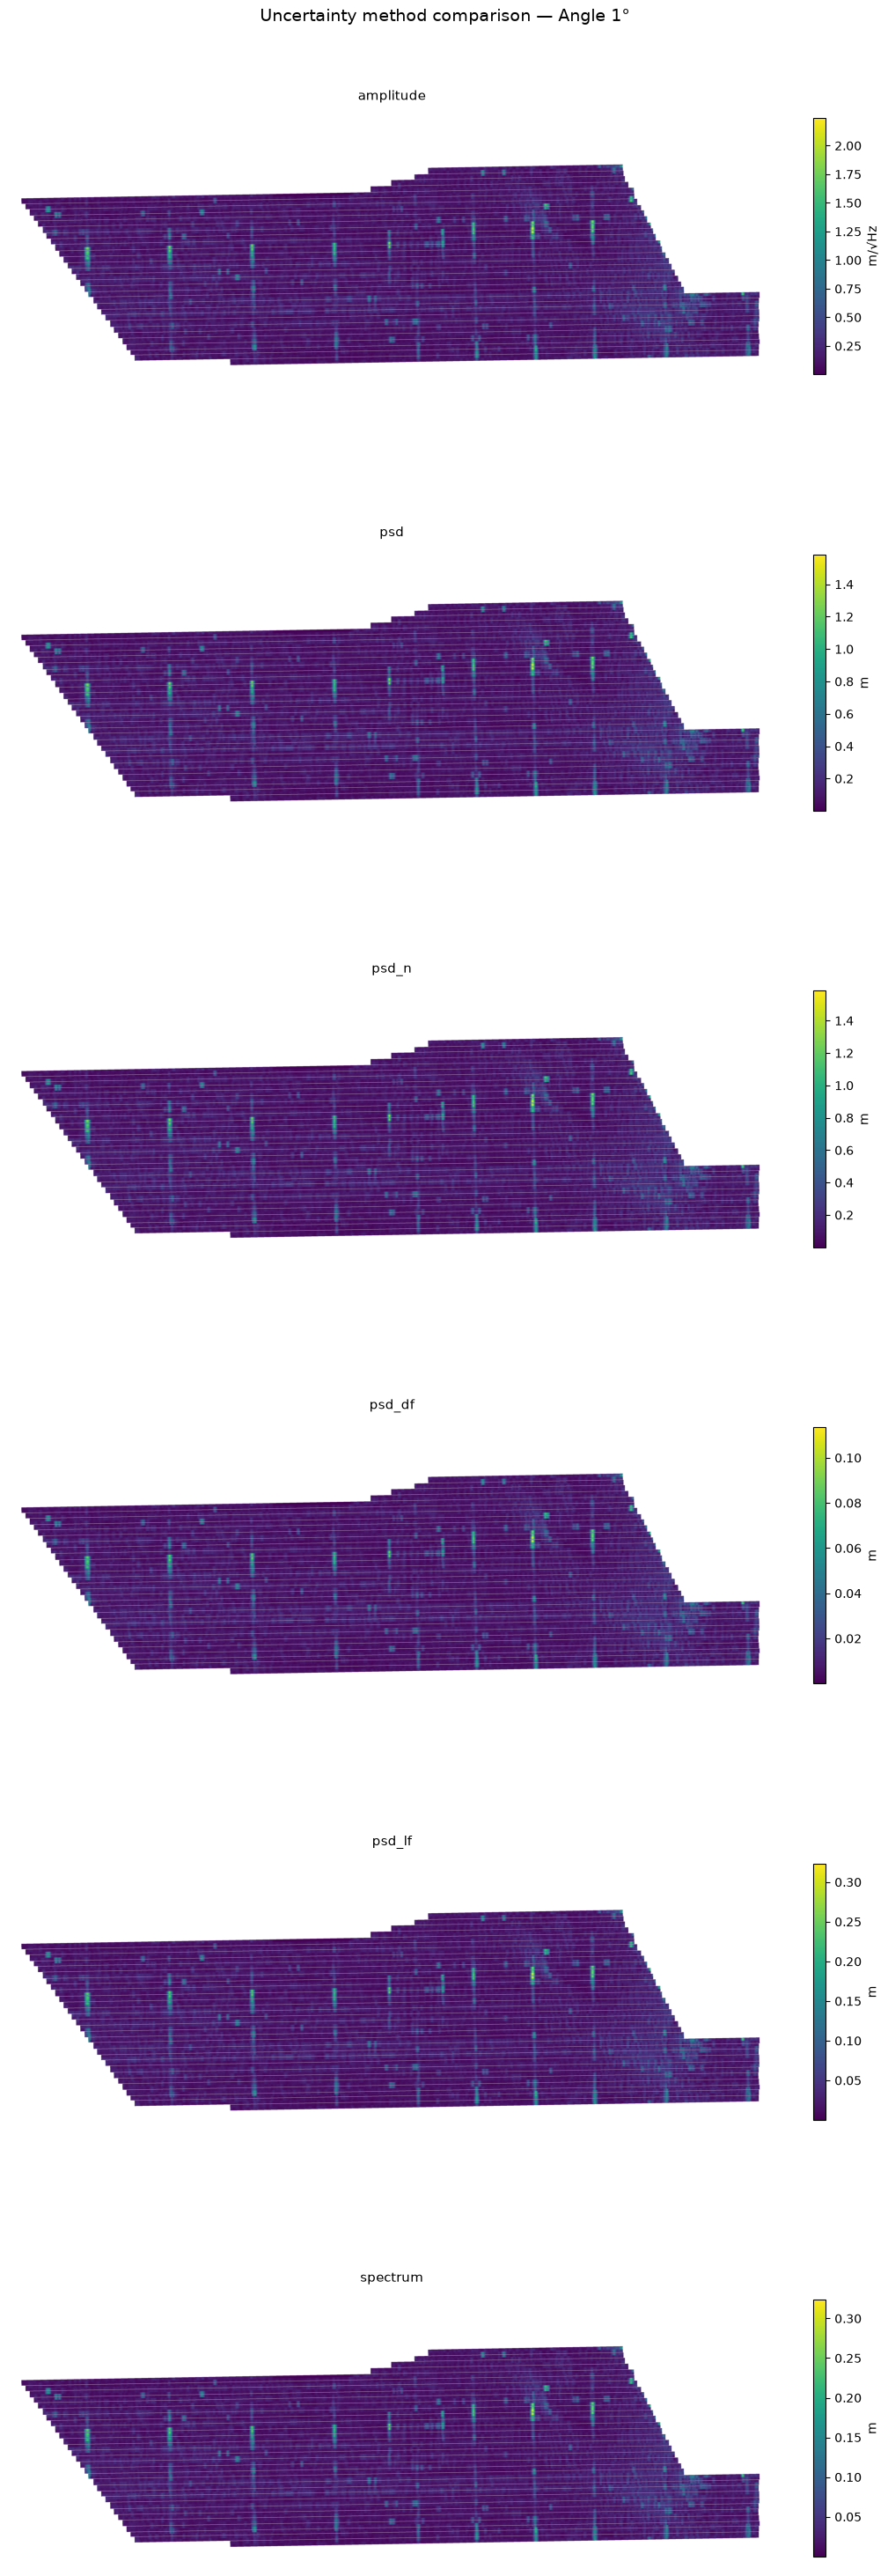

In [23]:
# --- Step B: Loop over methods and plot a row of subplots per angle ---
resolution = bathy_data['metadata']['resolution']

for angle, cache in angle_cache.items():
    n_methods = len(METHODS)
    fig, axes = plt.subplots(n_methods, 1, figsize=(10, 5 * n_methods),
                             constrained_layout=True)
    fig.suptitle(f'Uncertainty method comparison — Angle {angle}°', fontsize=14)
    for ax, method in zip(axes.flatten(), METHODS):
        print(f"Processing angle {angle}° with method '{method}' with ax {ax}...")
        uncertainty_raster = build_uncertainty_raster(
            peaks=cache['peaks'],
            restored_mask=cache['restored_mask'],
            current_depth_raster=cache['current_depth_raster'],
            resolution=resolution,
            method=method,
        )
        uncertainty_original = undo_rotation(
            raster=uncertainty_raster,
            angle_to_rotate=cache['angle_to_rotate'],
            original_shape=cache['current_mask'].shape,
        )
        im = ax.imshow(uncertainty_original, cmap='viridis')
        ax.set_title(method, fontsize=11)
        ax.axis('off')
        plt.colorbar(im, ax=ax, shrink=0.6,
                     label='m' if method != 'amplitude' else 'm/√Hz')

plt.show()

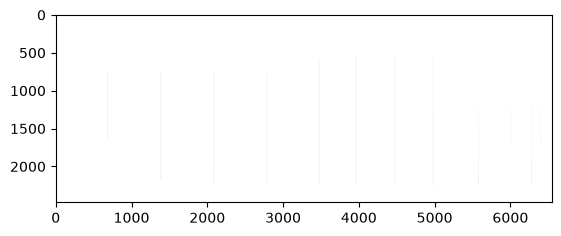

In [29]:
plt.imshow(depth_rasters[91], cmap='viridis')

Processing method 'amplitude' with ax Axes(0.125,0.77;0.775x0.11)...


ValueError: operands could not be broadcast together with shapes (1,2362,6506) (1,2475,6546) 

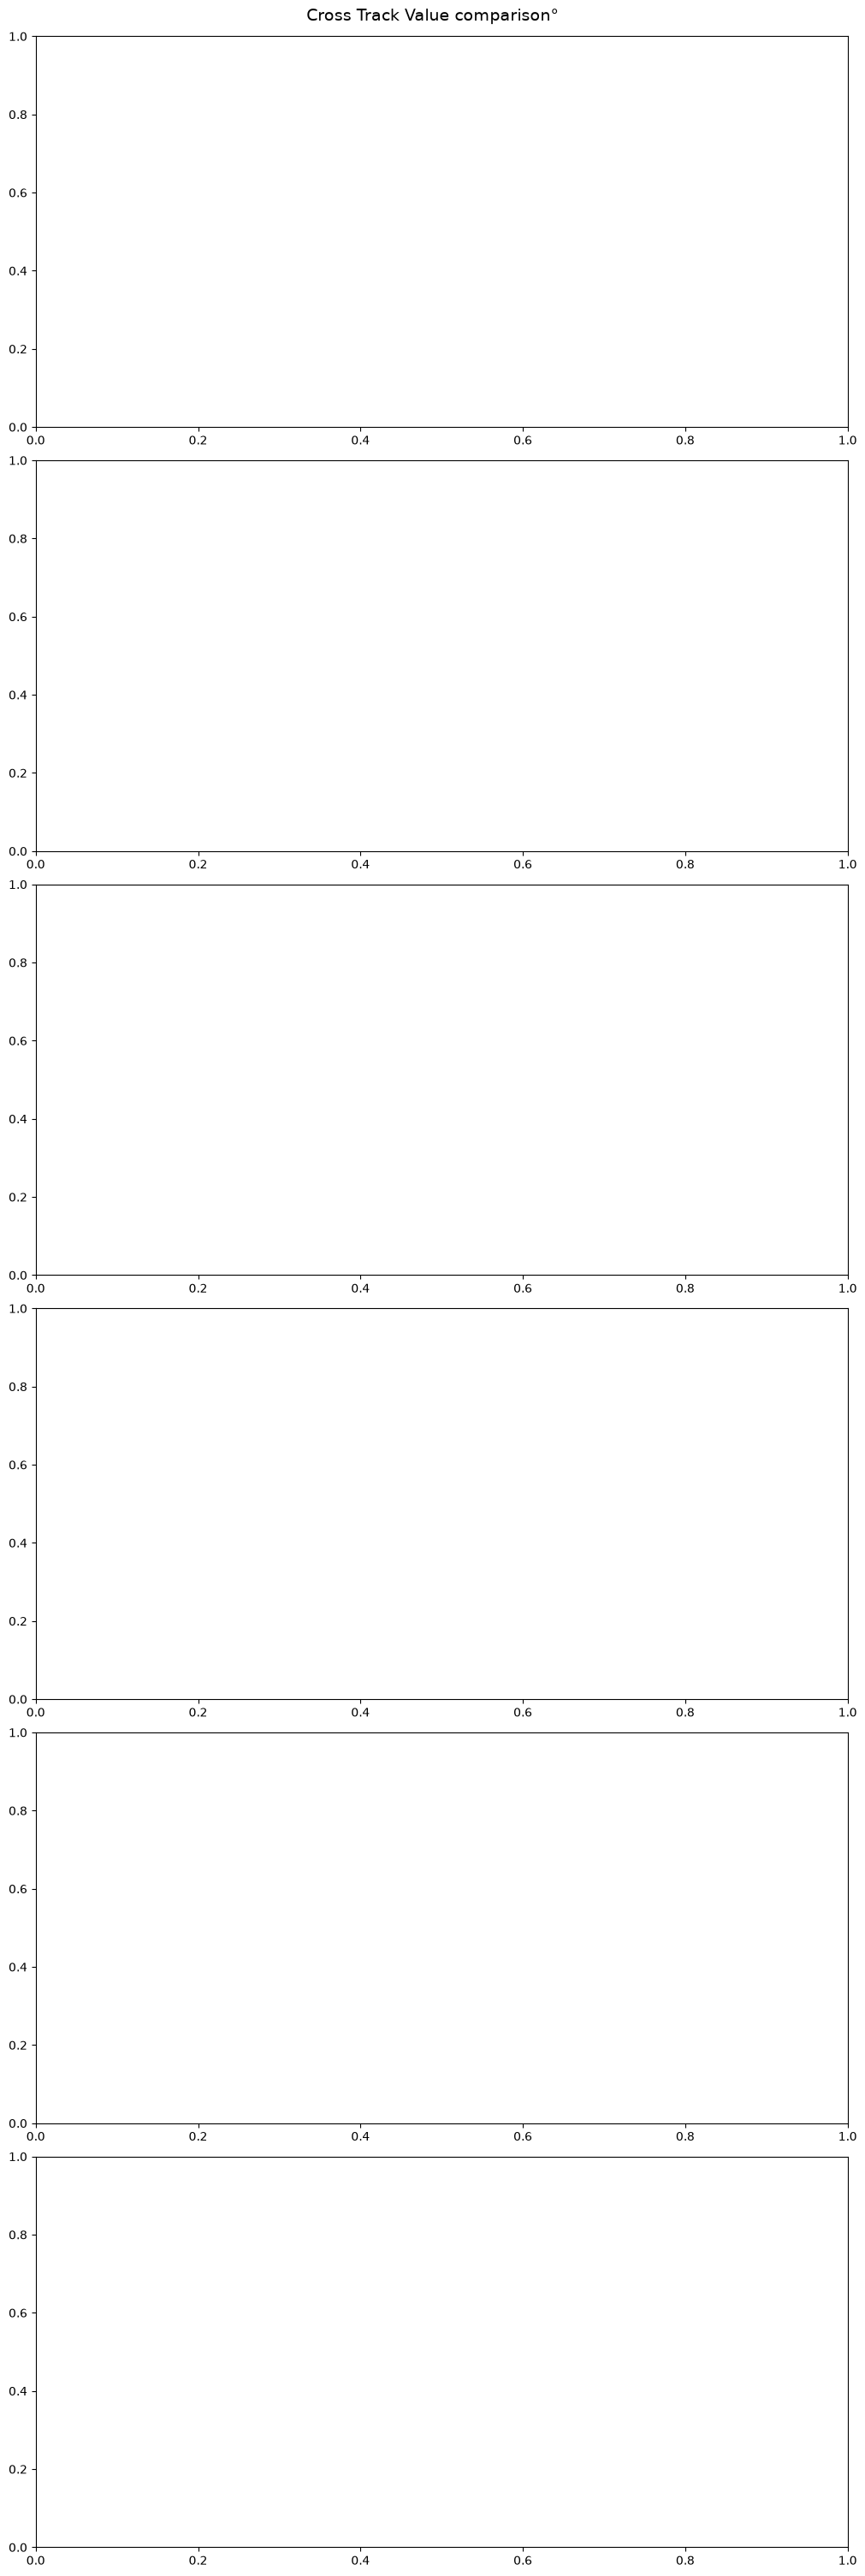

In [31]:
error = []
for angle, cache in angle_cache.items():
    n_methods = len(METHODS)
    fig, axes = plt.subplots(n_methods, 1, figsize=(10, 5 * n_methods),
                             constrained_layout=True)
    fig.suptitle(f'Cross Track Value comparison°', fontsize=14)
    for ax, method in zip(axes.flatten(), METHODS):
        print(f"Processing method '{method}' with ax {ax}...")
        uncertainty_raster = build_uncertainty_raster(
            peaks=cache['peaks'],
            restored_mask=cache['restored_mask'],
            current_depth_raster=cache['current_depth_raster'],
            resolution=resolution,
            method=method,
        )
        uncertainty_original = undo_rotation(
            raster=uncertainty_raster,
            angle_to_rotate=cache['angle_to_rotate'],
            original_shape=cache['current_mask'].shape,
        )

        error.append(np.mean(np.abs(uncertainty_original[np.any(depth_rasters[91])] -
                     depth_rasters[91][np.any(depth_rasters[91])])))




In [ ]:
plt.plot(error, METHODS)
plt.show()

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from skimage.draw import line
from skimage.transform import radon

In [2]:
# ---------------------------------------------------------
# 1. Create a synthetic test image with two line families
# ---------------------------------------------------------
size = 300
image = np.zeros((size, size), dtype=np.float32)

# Family 1: Horizontal lines (y-offsets = 60, 120, 180, 240)
for y in [60, 120, 180, 240]:
    rr, cc = line(y, 0, y, size - 1)
    image[rr, cc] = 1.0

# Family 2: Diagonal lines at 45 degrees
for offset in [-80, -20, 40, 100]:
    for x in range(size):
        y = x + offset
        if 0 <= y < size:
            image[y, x] = 1.0

In [3]:
# Add a touch of Gaussian noise to make it realistic
rng = np.random.default_rng(42)
noisy_image = image + rng.normal(0, 0.15, image.shape)
noisy_image = np.clip(noisy_image, 0, 1)

Text(0, 0.5, 'Row')

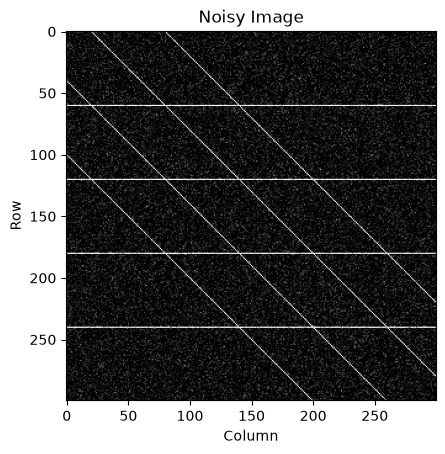

In [4]:
plt.figure()
# plt.imshow(noisy_image, cmap="gray", origin="lower")
plt.imshow(noisy_image, cmap="gray", vmin=0, vmax=1)
plt.title("Noisy Image")
plt.xlabel("Column")
plt.ylabel("Row")

Sinogram... done.


C:\Users\personal\miniconda3\envs\interpolation_uncertainty\Lib\site-packages\skimage\transform\radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


Text(0, 0.5, 'Variance')

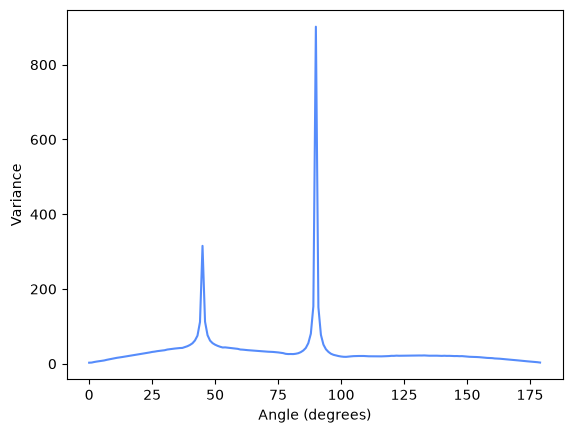

In [5]:
# ---------------------------------------------------------
# 2. Compute Radon Transform across 0-179 degrees
# ---------------------------------------------------------
thetas = np.arange(180)
print("Sinogram...", end=' ')
sinogram = radon(noisy_image, theta=thetas)
print("done.")
# ---------------------------------------------------------
# 3. Detect dominant orientation angles (Families)
# ---------------------------------------------------------
# Variance across projection coordinates identifies coherent angles
angle_scores = np.var(sinogram, axis=0)
# angle_scores = np.roll(angle_scores, 90)

plt.figure()
plt.plot(thetas, angle_scores)

plt.xlabel("Angle (degrees)")
plt.ylabel("Variance")

In [6]:


# Detect angle peaks (distance=20 ensures family separation)
angle_peak_indices, _ = find_peaks(
    angle_scores,
    prominence=0.3 * (angle_scores.max() - angle_scores.min()),
    distance=20,
)


detected_thetas_radon = thetas[angle_peak_indices]
detected_thetas_xy = (thetas[angle_peak_indices] + 90) % 180
# detected_thetas = np.roll(detected_thetas, 90)
print(f"Detected angles (xy): {detected_thetas_xy}")
print(f"Detected angles (radon): {detected_thetas_radon}")

Detected angles (xy): [135   0]
Detected angles (radon): [45 90]


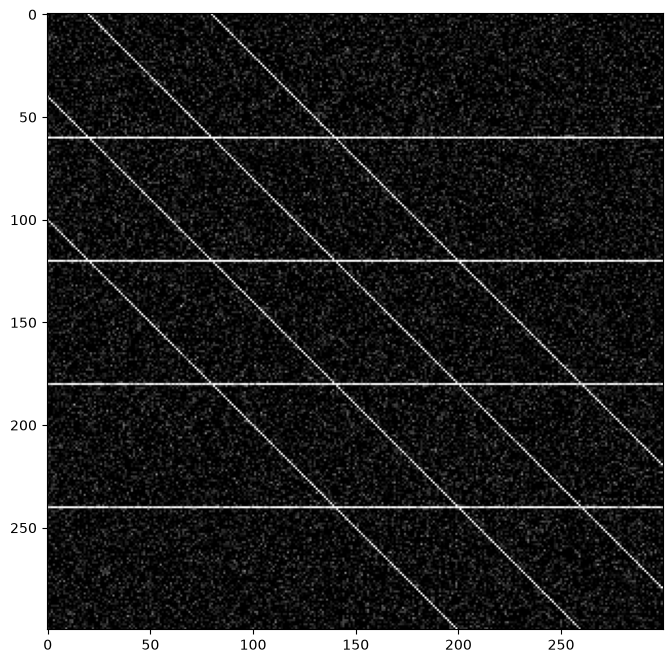

In [7]:
# ---------------------------------------------------------
# 4. Detect lines within each family and plot
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))
# ax.imshow(noisy_image, cmap="gray", origin="lower")
# ax.imshow(noisy_image, cmap="gray", origin="upper")
ax.imshow(noisy_image, cmap="gray")

Sinogram... done.
Detected angles (xy): [135   0]
Detected angles (radon): [45 90]


C:\Users\personal\miniconda3\envs\interpolation_uncertainty\Lib\site-packages\skimage\transform\radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


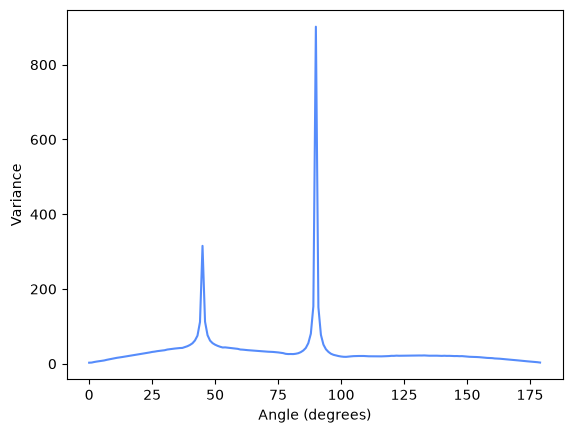

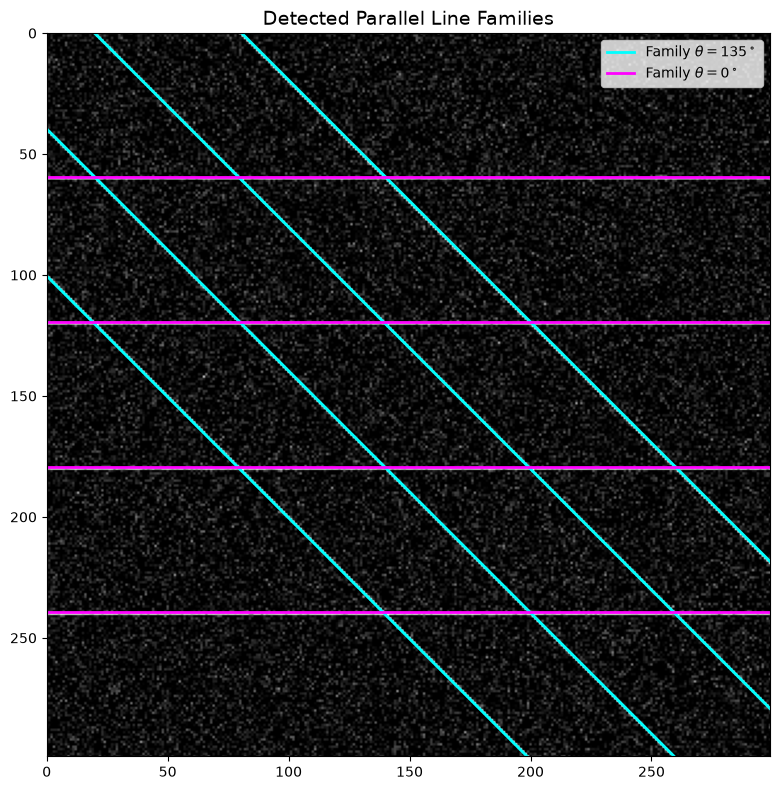

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from skimage.draw import line
from skimage.transform import radon


# ---------------------------------------------------------
# 1. Create a synthetic test image with two line families
# ---------------------------------------------------------
size = 300
image = np.zeros((size, size), dtype=np.float32)

# Family 1: Horizontal lines (y-offsets = 60, 120, 180, 240)
for y in [60, 120, 180, 240]:
    rr, cc = line(y, 0, y, size - 1)
    image[rr, cc] = 1.0

# Family 2: Diagonal lines at 45 degrees
for offset in [-80, -20, 40, 100]:
    for x in range(size):
        y = x + offset
        if 0 <= y < size:
            image[y, x] = 1.0

# Add a touch of Gaussian noise to make it realistic
rng = np.random.default_rng(42)
noisy_image = image + rng.normal(0, 0.15, image.shape)
noisy_image = np.clip(noisy_image, 0, 1)

# ---------------------------------------------------------
# 2. Compute Radon Transform across 0-179 degrees
# ---------------------------------------------------------
thetas = np.arange(180)
print("Sinogram...", end=' ')
sinogram = radon(noisy_image, theta=thetas)
print("done.")
# ---------------------------------------------------------
# 3. Detect dominant orientation angles (Families)
# ---------------------------------------------------------
# Variance across projection coordinates identifies coherent angles
angle_scores = np.var(sinogram, axis=0)
# angle_scores = np.roll(angle_scores, 90)

plt.figure()
plt.plot(thetas, angle_scores)

plt.xlabel("Angle (degrees)")
plt.ylabel("Variance")
# Detect angle peaks (distance=20 ensures family separation)
angle_peak_indices, _ = find_peaks(
    angle_scores,
    prominence=0.3 * (angle_scores.max() - angle_scores.min()),
    distance=20,
)

detected_thetas_radon = thetas[angle_peak_indices]
detected_thetas_xy = (thetas[angle_peak_indices] + 90) % 180
# detected_thetas = np.roll(detected_thetas, 90)
print(f"Detected angles (xy): {detected_thetas_xy}")
print(f"Detected angles (radon): {detected_thetas_radon}")

# ---------------------------------------------------------
# 4. Detect lines within each family and plot
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))
# ax.imshow(noisy_image, cmap="gray", origin="lower")
# ax.imshow(noisy_image, cmap="gray", origin="upper")
ax.imshow(noisy_image, cmap="gray")

# Center coordinates used internally by skimage.transform.radon
x0, y0 = (size - 1) / 2.0, (size - 1) / 2.0
num_projections = sinogram.shape[0]
r_coords = np.arange(num_projections) - num_projections // 2

colors = ["cyan", "magenta", "yellow", "lime", "orange"]

for i, (angle_idx, theta_deg) in enumerate(
        zip(angle_peak_indices, detected_thetas_xy)):
    color = colors[i % len(colors)]
    theta_rad = np.deg2rad(theta_deg)
    cos_t = np.cos(theta_rad)
    sin_t = np.sin(theta_rad)

    # Slice the sinogram at this angle and locate spatial peaks
    slice_1d = sinogram[:, angle_idx]
    s_peak_indices, _ = find_peaks(
        slice_1d, prominence=0.25 * (slice_1d.max() - slice_1d.min()), distance=15
    )

    detected_s_values = r_coords[s_peak_indices]

    # Draw each detected line
    for s in detected_s_values:
        # Solve: s = (x - x0)*cos(theta) + (y - y0)*sin(theta)
        # Check intersections with image boundaries [0, size-1]
        pts = []

        if abs(sin_t) > 1e-4:
            # x = 0 and x = size - 1
            y_left = y0 + (s - (0 - x0) * cos_t) / sin_t
            y_right = y0 + (s - (size - 1 - x0) * cos_t) / sin_t
            if 0 <= y_left < size:
                pts.append((0, y_left))
            if 0 <= y_right < size:
                pts.append((size - 1, y_right))

        if abs(cos_t) > 1e-4:
            # y = 0 and y = size - 1
            x_top = x0 + (s - (0 - y0) * sin_t) / cos_t
            x_bottom = x0 + (s - (size - 1 - y0) * sin_t) / cos_t
            if 0 <= x_top < size:
                pts.append((x_top, 0))
            if 0 <= x_bottom < size:
                pts.append((x_bottom, size - 1))

        # Filter duplicates (e.g. corner intersections) and draw
        unique_pts = []
        for p in pts:
            if not any(np.allclose(p, u, atol=1.0) for u in unique_pts):
                unique_pts.append(p)

        if len(unique_pts) >= 2:
            (x1, y1), (x2, y2) = unique_pts[0], unique_pts[1]
            ax.plot(
                [y1, y2],
                [x1, x2],
                color=color,
                linewidth=2,
                label=f"Family $\\theta={theta_deg}^\\circ$"
                if s == detected_s_values[0]
                else "",
            )

ax.set_xlim(0, size - 1)
ax.set_ylim(size - 1, 0)  # Standard image coordinates (y increases downward)
ax.set_title("Detected Parallel Line Families", fontsize=14)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

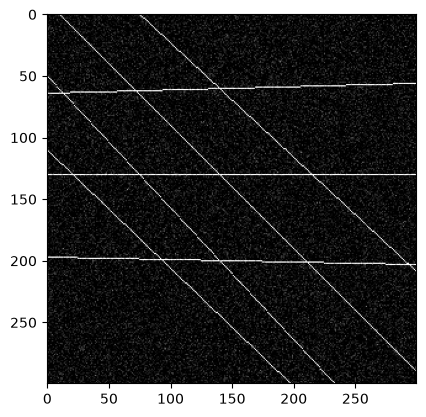

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter
from scipy.signal import find_peaks
from skimage.draw import line
from skimage.transform import radon

# ---------------------------------------------------------
# 1. Create a synthetic test image with slight slope variations
# ---------------------------------------------------------
size = 300
image = np.zeros((size, size), dtype=np.float32)

# Family 1: Nominal ~90° (horizontal), but with slight tilts
# e.g., lines at 89°, 90°, 92°
# for y0_line, slope_offset in zip([60, 130, 200, 260], [-4, 0, 3, -2]):
for y0_line, slope_offset in zip([60, 130, 200], [-4, 0, 3]):
    rr, cc = line(
        int(np.clip(y0_line - slope_offset, 0, size - 1)),
        0,
        int(np.clip(y0_line + slope_offset, 0, size - 1)),
        size - 1,
    )
    image[rr, cc] = 1.0

# Family 2: Nominal ~45° diagonal, but tilted between 43° and 47°
# Using standard Cartesian coordinates to draw varied slopes
x_vals = np.arange(size)
for offset, slope in zip([-70, -10, 50, 110], [0.93, 1.0, 1.07, 0.96]):
    y_vals = np.round(slope * x_vals + offset).astype(int)
    valid = (y_vals >= 0) & (y_vals < size)
    image[y_vals[valid], x_vals[valid]] = 1.0

# Add noise
rng = np.random.default_rng(42)
noisy_image = np.clip(image + rng.normal(0, 0.12, image.shape), 0, 1)

plt.figure()
plt.imshow(noisy_image, cmap="gray", origin="upper")

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter
from scipy.signal import find_peaks
from skimage.draw import line
from skimage.transform import radon

# ---------------------------------------------------------
# 1. Create a synthetic test image with slight slope variations
# ---------------------------------------------------------
size = 300
image = np.zeros((size, size), dtype=np.float32)

# Family 1: Nominal ~90° (horizontal), but with slight tilts
# e.g., lines at 89°, 90°, 92°
for y0_line, slope_offset in zip([60, 130, 200, 260], [-4, 0, 3, -2]):
# for y0_line, slope_offset in zip([60, 130, 200], [-4, 0, 3]):
    rr, cc = line(
        int(np.clip(y0_line - slope_offset, 0, size - 1)),
        0,
        int(np.clip(y0_line + slope_offset, 0, size - 1)),
        size - 1,
    )
    image[rr, cc] = 1.0

# Family 2: Nominal ~45° diagonal, but tilted between 43° and 47°
# Using standard Cartesian coordinates to draw varied slopes
x_vals = np.arange(size)
for offset, slope in zip([-70, -10, 50, 110], [0.93, 1.0, 1.07, 0.96]):
    y_vals = np.round(slope * x_vals + offset).astype(int)
    valid = (y_vals >= 0) & (y_vals < size)
    image[y_vals[valid], x_vals[valid]] = 1.0

# Add noise
rng = np.random.default_rng(42)
noisy_image = np.clip(image + rng.normal(0, 0.12, image.shape), 0, 1)

In [2]:
# ---------------------------------------------------------
# 2. Compute Radon Transform (1-degree resolution)
# ---------------------------------------------------------
thetas = np.arange(180)
sinogram = radon(noisy_image, theta=thetas)

# print(f"sinogram shape: {sinogram.shape}")
# sinogram = np.roll(sinogram, 90)
# ---------------------------------------------------------
# 3. Detect dominant "nominal" orientation peaks
# ---------------------------------------------------------
angle_scores = np.var(sinogram, axis=0)


# peak detection
major_peak_indices, _ = find_peaks(
    angle_scores,
    prominence=0.25 * (angle_scores.max() - angle_scores.min()),
    distance=20,
)

# major_peak_indices = (major_peak_indices + 90) % 180



# nominal_thetas = thetas[major_peak_indices]
nominal_thetas = (thetas[major_peak_indices] + 90) % 180
print(f"Nominal angles: {nominal_thetas}")

Nominal angles: [135   0]


C:\Users\personal\miniconda3\envs\interpolation_uncertainty\Lib\site-packages\skimage\transform\radon_transform.py:74: UserWarning: Radon transform: image must be zero outside the reconstruction circle
  warn(


In [3]:
# ---------------------------------------------------------
# 4. Extract lines within tolerance window around each family
# ---------------------------------------------------------
ANGULAR_TOLERANCE = 3  # ±3 degrees (e.g. 45° covers 42° to 48°)
num_projections = sinogram.shape[0] # largest dimension * sqrt(2)
r_coords = np.arange(num_projections) - num_projections // 2
x0, y0 = (size - 1) / 2.0, (size - 1) / 2.0 #center of the image

In [6]:
sinogram.shape

(300, 180)

In [4]:
num_projections

300

In [5]:
r_coords

array([-150, -149, -148, -147, -146, -145, -144, -143, -142, -141, -140,
       -139, -138, -137, -136, -135, -134, -133, -132, -131, -130, -129,
       -128, -127, -126, -125, -124, -123, -122, -121, -120, -119, -118,
       -117, -116, -115, -114, -113, -112, -111, -110, -109, -108, -107,
       -106, -105, -104, -103, -102, -101, -100,  -99,  -98,  -97,  -96,
        -95,  -94,  -93,  -92,  -91,  -90,  -89,  -88,  -87,  -86,  -85,
        -84,  -83,  -82,  -81,  -80,  -79,  -78,  -77,  -76,  -75,  -74,
        -73,  -72,  -71,  -70,  -69,  -68,  -67,  -66,  -65,  -64,  -63,
        -62,  -61,  -60,  -59,  -58,  -57,  -56,  -55,  -54,  -53,  -52,
        -51,  -50,  -49,  -48,  -47,  -46,  -45,  -44,  -43,  -42,  -41,
        -40,  -39,  -38,  -37,  -36,  -35,  -34,  -33,  -32,  -31,  -30,
        -29,  -28,  -27,  -26,  -25,  -24,  -23,  -22,  -21,  -20,  -19,
        -18,  -17,  -16,  -15,  -14,  -13,  -12,  -11,  -10,   -9,   -8,
         -7,   -6,   -5,   -4,   -3,   -2,   -1,   

In [7]:
# 2D local maximum mask to prevent double-counting adjacent angles/pixels
neighborhood_size = (7, 3)  # (s-radius, theta-radius)
local_max = maximum_filter(sinogram, size=neighborhood_size) == sinogram
min_intensity = 0.35 * sinogram.max()

Nominal angles: [135   0]


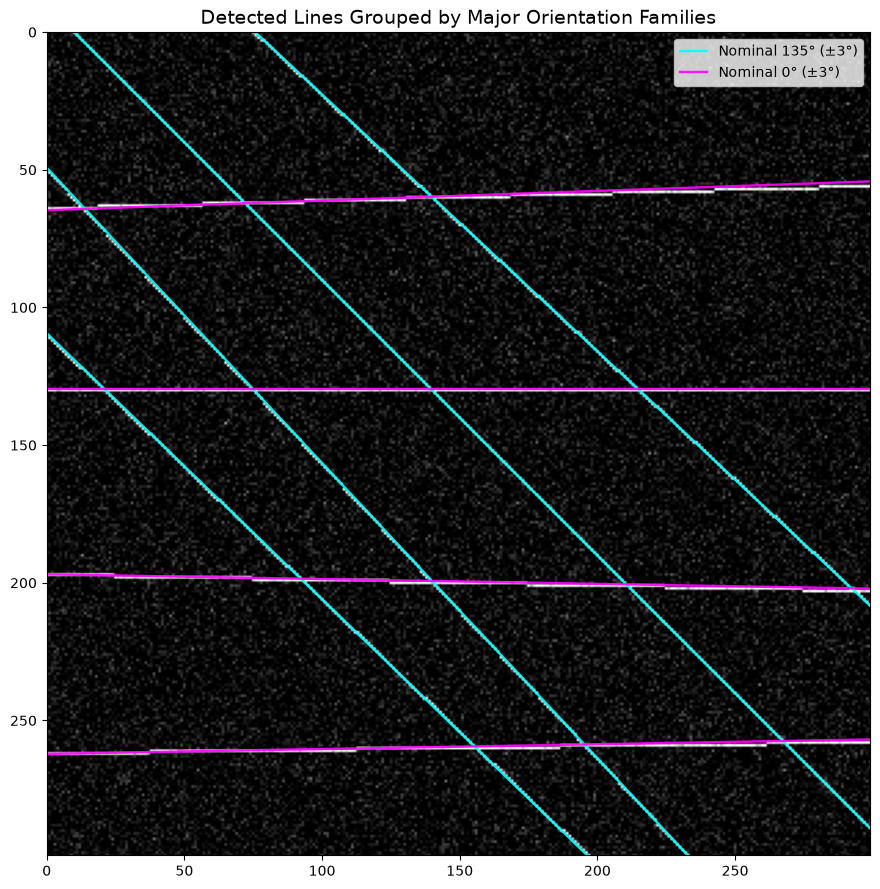

In [12]:





fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(noisy_image, cmap="gray")
colors = ["cyan", "magenta", "yellow", "lime"]


for i, (center_idx, nominal_theta) in enumerate(
    zip(major_peak_indices, nominal_thetas)
):
    color = colors[i % len(colors)]

    # Define the angular range for this family
    theta_min = max(0, center_idx - ANGULAR_TOLERANCE)
    theta_max = min(179, center_idx + ANGULAR_TOLERANCE)

    # Find 2D peak points inside this angular window
    band_mask = np.zeros_like(sinogram, dtype=bool)
    band_mask[:, theta_min : theta_max + 1] = True

    # Candidate peaks: must be local 2D maximum, above noise, and in angle band
    peak_candidates = local_max & band_mask & (sinogram >= min_intensity)
    s_indices, angle_sub_indices = np.where(peak_candidates)
    # angle_sub_indices = (angle_sub_indices + 90) % 180
    first_line_of_family = True
    # print(f"angle_sub_indices: {angle_sub_indices}")

    for s_idx, a_idx in zip(s_indices, angle_sub_indices):
        # print(f"s_idx: {s_idx}, a_idx: {a_idx}")
        s_val = r_coords[s_idx]
        actual_theta_deg = (thetas[a_idx] + 90)
        actual_theta_rad = np.deg2rad(actual_theta_deg)

        cos_t = np.cos(actual_theta_rad)
        sin_t = np.sin(actual_theta_rad)

        # Intersect line: s = (x - x0)*cos(theta) + (y - y0)*sin(theta)
        pts = []
        #
        if abs(sin_t) > 1e-4:
            y_left = y0 + (s_val - (0 - x0) * cos_t) / sin_t
            y_right = y0 + (s_val - (size - 1 - x0) * cos_t) / sin_t
            if 0 <= y_left < size:
                pts.append((0, y_left))
            if 0 <= y_right < size:
                pts.append((size - 1, y_right))

        if abs(cos_t) > 1e-4:
            x_top = x0 + (s_val - (0 - y0) * sin_t) / cos_t
            x_bottom = x0 + (s_val - (size - 1 - y0) * sin_t) / cos_t
            if 0 <= x_top < size:
                pts.append((x_top, 0))
            if 0 <= x_bottom < size:
                pts.append((x_bottom, size - 1))

        # Remove duplicate corner matches
        unique_pts = []
        for p in pts:
            if not any(np.allclose(p, u, atol=1.0) for u in unique_pts):
                unique_pts.append(p)

        if len(unique_pts) >= 2:
            (x1, y1), (x2, y2) = unique_pts[0], unique_pts[1]
            label_text = (
                f"Nominal {nominal_theta}° (±{ANGULAR_TOLERANCE}°)"
                if first_line_of_family
                else ""
            )
            ax.plot(
                [y1, y2],
                [x1, x2],
                color=color,
                linewidth=1.75,
                alpha=0.9,
                label=label_text,
            )
            first_line_of_family = False

ax.set_xlim(0, size - 1)
ax.set_ylim(size - 1, 0)
ax.set_title(
    "Detected Lines Grouped by Major Orientation Families", fontsize=14
)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# Draw each detected line
    for s in detected_s_values:
        # Solve: s = (x - x0)*cos(theta) + (y - y0)*sin(theta)
        # Check intersections with image boundaries [0, size-1]
        pts = []

        if abs(sin_t) > 1e-4:
            # x = 0 and x = size - 1
            y_left = y0 + (s - (0 - x0) * cos_t) / sin_t
            y_right = y0 + (s - (size - 1 - x0) * cos_t) / sin_t
            if 0 <= y_left < size:
                pts.append((0, y_left))
            if 0 <= y_right < size:
                pts.append((size - 1, y_right))

        if abs(cos_t) > 1e-4:
            # y = 0 and y = size - 1
            x_top = x0 + (s - (0 - y0) * sin_t) / cos_t
            x_bottom = x0 + (s - (size - 1 - y0) * sin_t) / cos_t
            if 0 <= x_top < size:
                pts.append((x_top, 0))
            if 0 <= x_bottom < size:
                pts.append((x_bottom, size - 1))

        # Filter duplicates (e.g. corner intersections) and draw
        unique_pts = []
        for p in pts:
            if not any(np.allclose(p, u, atol=1.0) for u in unique_pts):
                unique_pts.append(p)

        if len(unique_pts) >= 2:
            (x1, y1), (x2, y2) = unique_pts[0], unique_pts[1]
            ax.plot(
                [y1, y2],
                [x1, x2],
                color=color,
                linewidth=2,
                label=f"Family $\\theta={theta_deg}^\\circ$"
                if s == detected_s_values[0]
                else "",
            )